# Learning Companion — US Regional Sales Analysis

A practical guide to the techniques used in this project: Python & EDA, SQL analysis, and Power BI / DAX.

Each topic includes a short definition, why it is useful, and an example or reusable pattern. Examples are simplified for learning; refer to the analysis notebooks and SQL modules for the complete project implementation.

> **Metric assumptions used in this project:** Gross Sales = Order Quantity × Unit Price; Discount Amount = Gross Sales × Discount Applied; Net Sales = Gross Sales − Discount Amount; Profit = Net Sales − Total Cost. These are analytical assumptions based on available fields, not verified accounting definitions.

## 1. Python & Exploratory Data Analysis (EDA)

**EDA** means inspecting, summarizing, and visualizing data to understand its structure, quality, distributions, and relationships before drawing conclusions.

Questions we ask: How many rows? Which data types? Missing or duplicate values? What are the patterns and outliers? Do the results make sense?

### Libraries
- **Pandas (`pd`)**: tabular data manipulation; DataFrame and Series.
- **Matplotlib (`plt`)**: general plotting.
- **Seaborn (`sns`)**: statistical visualizations built on Matplotlib.
- **sqlite3**: Python's built-in SQLite interface; no pip install required.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

### 1.1 Load and inspect data

`read_csv()` loads a CSV into a DataFrame. `head()`, `shape`, `info()`, `describe()`, `isna().sum()`, and `duplicated().sum()` are common inspection tools.

In [2]:
# Adjust the relative path if running this notebook from a different folder.
# df = pd.read_csv("../data/raw/US_Regional_Sales_Data.csv")

sample = pd.DataFrame({
    "SalesChannel": ["Online", "In-Store", "Online", "Wholesale"],
    "OrderQuantity": [3, 2, 5, 4],
    "UnitPrice": [100, 150, 80, 120],
    "DiscountApplied": [0.10, 0.05, 0.15, 0.075],
    "UnitCost": [60, 90, 50, 70]
})
sample.head()

,SalesChannel,OrderQuantity,UnitPrice,DiscountApplied,UnitCost
0,Online,3,100,0.100,60
1,In-Store,2,150,0.050,90
2,Online,5,80,0.150,50
3,Wholesale,4,120,0.075,70


### 1.2 Cleaning and calculated columns

Cleaning makes data consistent: standardize names, fix data types, handle missing values, and remove formatting characters. A calculated column derives a new value from existing columns.

In [3]:
# Convert comma-formatted numeric text into numbers
prices = pd.Series(["1,250.50", "980.00", "2,100.75"])
prices = pd.to_numeric(prices.str.replace(",", "", regex=False))
prices

0    1250.50
1     980.00
2    2100.75
dtype: float64

In [4]:
# Project's analytical metric pattern
sample["GrossSales"] = sample["OrderQuantity"] * sample["UnitPrice"]
sample["DiscountAmount"] = sample["GrossSales"] * sample["DiscountApplied"]
sample["NetSales"] = sample["GrossSales"] - sample["DiscountAmount"]
sample["TotalCost"] = sample["OrderQuantity"] * sample["UnitCost"]
sample["Profit"] = sample["NetSales"] - sample["TotalCost"]
sample

,SalesChannel,OrderQuantity,UnitPrice,DiscountApplied,UnitCost,GrossSales,DiscountAmount,NetSales,TotalCost,Profit
0,Online,3,100,0.100,60,300,30.0,270.0,180,90.0
1,In-Store,2,150,0.050,90,300,15.0,285.0,180,105.0
2,Online,5,80,0.150,50,400,60.0,340.0,250,90.0
3,Wholesale,4,120,0.075,70,480,36.0,444.0,280,164.0


### 1.3 Grouping and aggregation

Aggregation summarizes many rows into metrics. `groupby()` forms groups; `sum`, `mean`, `count`, `nunique`, `min`, and `max` summarize them.

In [5]:
channel_summary = (
    sample.groupby("SalesChannel", as_index=False)
          .agg(
              Orders=("SalesChannel", "size"),
              NetSales=("NetSales", "sum"),
              Profit=("Profit", "sum")
          )
)
channel_summary

,SalesChannel,Orders,NetSales,Profit
0,In-Store,1,285.0,105.0
1,Online,2,610.0,180.0
2,Wholesale,1,444.0,164.0


### 1.4 Bar charts and Seaborn

A **bar chart** compares values across categories, such as sales by channel. Sort bars, label axes, and keep category counts manageable.

**Seaborn** makes statistical charts convenient: `barplot`, `histplot`, `boxplot`, `scatterplot`, and `heatmap`.

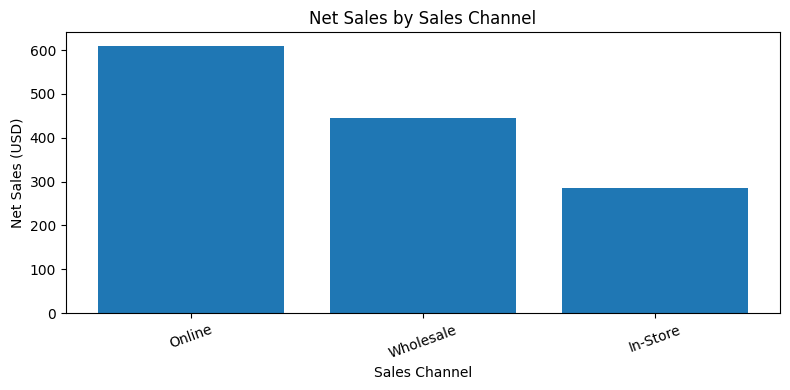

In [6]:
channel_summary = channel_summary.sort_values("NetSales", ascending=False)
plt.figure(figsize=(8, 4))
plt.bar(channel_summary["SalesChannel"], channel_summary["NetSales"])
plt.title("Net Sales by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Net Sales (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

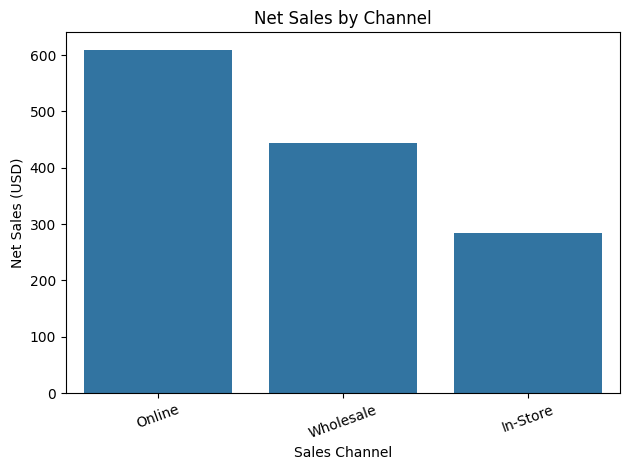

In [7]:
sns.barplot(data=channel_summary, x="SalesChannel", y="NetSales")
plt.title("Net Sales by Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Net Sales (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 1.5 Pareto analysis

**Pareto analysis** ranks contributors from largest to smallest and calculates cumulative contribution. It answers questions like “How many products account for 80% of sales?”

The 80/20 principle is a heuristic, not a rule. In this project, product sales were broadly distributed: 36 of 47 products were needed to reach about 80% of product sales.

Steps: aggregate → sort descending → calculate share → calculate cumulative share → find the count at a target threshold.

In [8]:
pareto = channel_summary.sort_values("NetSales", ascending=False).copy()
pareto["SalesShare"] = pareto["NetSales"] / pareto["NetSales"].sum()
pareto["CumulativeShare"] = pareto["SalesShare"].cumsum()
pareto

,SalesChannel,Orders,NetSales,Profit,SalesShare,CumulativeShare
1,Online,2,610.0,180.0,0.455564,0.455564
2,Wholesale,1,444.0,164.0,0.331591,0.787155
0,In-Store,1,285.0,105.0,0.212845,1.000000


In [9]:
# General product-level pattern:
# product_sales = df.groupby("ProductID")["NetSales"].sum().sort_values(ascending=False)
# pareto = product_sales.reset_index(name="NetSales")
# pareto["SalesShare"] = pareto["NetSales"] / pareto["NetSales"].sum()
# pareto["CumulativeShare"] = pareto["SalesShare"].cumsum()
# products_for_80 = (pareto["CumulativeShare"] < 0.80).sum() + 1

### 1.6 Correlation and validation

**Correlation** measures association between variables: Pearson for linear association; Spearman for rank-based monotonic association. Values range from −1 to +1. Correlation does **not** prove causation.

**Validation** checks expected conditions (row counts, missing values, uniqueness). **Reconciliation** compares results from Python, SQL, and Power BI. Small differences around one cent can arise from floating-point arithmetic; investigate discrepancies rather than rounding order-level values prematurely.

In [10]:
# Examples when these columns exist in your prepared DataFrame:
# df[["DiscountApplied", "ProfitMargin"]].corr(method="pearson")
# df[["DiscountApplied", "ProfitMargin"]].corr(method="spearman")

## 2. SQL for Business Analysis

SQL queries relational data. This project used SQLite.

### Core commands
- `SELECT`: choose columns/expressions
- `FROM`: source table
- `WHERE`: filter rows before grouping
- `GROUP BY`: aggregate by category
- `HAVING`: filter aggregated groups
- `ORDER BY`: sort results
- `LIMIT`: limit rows
- `CASE`: conditional logic
- `JOIN`: combine tables
- `SUM`, `COUNT`, `AVG`, `MIN`, `MAX`: aggregate functions

A useful logical order is: `FROM` → `WHERE` → `GROUP BY` → `HAVING` → `SELECT` → `ORDER BY` → `LIMIT`.

### 2.1 Aggregation and CASE

`CASE` is SQL's conditional expression, similar to `if/else` in Python.

```sql
-- Net sales by channel
SELECT
    SalesChannel,
    SUM(OrderQuantity * UnitPrice * (1 - DiscountApplied)) AS NetSales
FROM regional_sales
GROUP BY SalesChannel
ORDER BY NetSales DESC;
```

```sql
-- Group orders into discount bands
SELECT
    CASE
        WHEN DiscountApplied < 0.10 THEN 'Below 10%'
        WHEN DiscountApplied < 0.20 THEN '10% to 19.99%'
        WHEN DiscountApplied < 0.30 THEN '20% to 29.99%'
        ELSE '30% and above'
    END AS DiscountCategory,
    COUNT(*) AS Orders
FROM regional_sales
GROUP BY DiscountCategory
ORDER BY Orders DESC;
```

### 2.2 CTEs — Common Table Expressions (detailed)

A **CTE** is a named temporary result set defined with `WITH`, available to the statement that follows. It is not a permanent table.

Why use CTEs?
- Break a complex query into readable stages.
- Name intermediate calculations.
- Avoid repeating subqueries.
- Make each step easier to inspect and validate.

Structure:
```sql
WITH first_step AS (
    SELECT ...
),
second_step AS (
    SELECT ...
    FROM first_step
)
SELECT ...
FROM second_step;
```
Later CTEs can use earlier CTEs.

```sql
-- Stage 1: calculate row-level net sales
-- Stage 2: aggregate the calculation by channel
WITH order_metrics AS (
    SELECT
        SalesChannel,
        OrderQuantity * UnitPrice * (1 - DiscountApplied) AS NetSales
    FROM regional_sales
),
channel_summary AS (
    SELECT SalesChannel, SUM(NetSales) AS TotalNetSales
    FROM order_metrics
    GROUP BY SalesChannel
)
SELECT *
FROM channel_summary
ORDER BY TotalNetSales DESC;
```

### 2.3 Window functions (detailed)

A **window function** calculates across related rows while keeping each row in the result. `GROUP BY` collapses rows; a window function generally preserves them.

- `OVER()` defines the window.
- `PARTITION BY` divides rows into groups.
- `ORDER BY` defines order inside the window.
- `LAG()` / `LEAD()` access previous / next rows.
- `ROW_NUMBER()`, `RANK()`, `DENSE_RANK()` rank rows.
- `SUM() OVER()` can calculate a total or running total.

Pattern:
```sql
function_name(expression) OVER (
    PARTITION BY group_column
    ORDER BY sort_column
)
```

```sql
-- Sales share: keep each channel row and add the grand total
WITH channel_sales AS (
    SELECT
        SalesChannel,
        SUM(OrderQuantity * UnitPrice * (1 - DiscountApplied)) AS NetSales
    FROM regional_sales
    GROUP BY SalesChannel
)
SELECT
    SalesChannel,
    NetSales,
    SUM(NetSales) OVER () AS AllSales,
    100.0 * NetSales / SUM(NetSales) OVER () AS SalesSharePct
FROM channel_sales
ORDER BY NetSales DESC;
```

```sql
-- LAG: compare each month with the previous month
WITH monthly_sales AS (
    SELECT
        substr(OrderDate, 7, 4) || '-' || substr(OrderDate, 4, 2) AS YearMonth,
        SUM(OrderQuantity * UnitPrice * (1 - DiscountApplied)) AS NetSales
    FROM regional_sales
    GROUP BY YearMonth
),
monthly_comparison AS (
    SELECT
        YearMonth,
        NetSales,
        LAG(NetSales) OVER (ORDER BY YearMonth) AS PreviousMonthSales
    FROM monthly_sales
)
SELECT
    YearMonth,
    NetSales,
    PreviousMonthSales,
    100.0 * (NetSales - PreviousMonthSales) / PreviousMonthSales AS MoMGrowthPct
FROM monthly_comparison
ORDER BY YearMonth;
```

**Where used in this project:** CTEs structure multi-stage analysis across SQL modules. Module 05 uses `LAG()` for month-over-month growth. Module 07 uses a cumulative `SUM() OVER(ORDER BY NetSales DESC)` for product contribution. Contribution analyses use `SUM(NetSales) OVER()` for total sales and shares.

**Remember:** CTE = organize query steps; window function = calculate across related rows. They complement one another but do different jobs.

## 3. Power BI & DAX

### 3.1 Data model

Power BI connects data, transforms it, models relationships, calculates measures, and creates interactive reports.

In this project:
- `RegionalSales` is the transaction/fact table.
- `DateTable` is a calendar table with one row per date.
- `RegionalSales[OrderDate]` relates to `DateTable[Date]`.
- The relationship is many sales rows to one date row.

A dedicated Date table supports consistent Year, Month, Quarter, and Year-Month filtering.

```dax
-- DAX calculated table pattern for a calendar table
DateTable =
ADDCOLUMNS(
    CALENDAR(DATE(2018, 1, 1), DATE(2020, 12, 31)),
    "Year", YEAR([Date]),
    "Month Number", MONTH([Date]),
    "Month Name", FORMAT([Date], "MMMM"),
    "Quarter", "Q" & FORMAT([Date], "Q"),
    "Year-Month", FORMAT([Date], "YYYY-MM")
)
```

### 3.2 What is DAX?

**DAX (Data Analysis Expressions)** is Power BI's formula language.

- **Calculated column:** computed for each row and stored in the model.
- **Measure:** evaluated dynamically according to the visual's filter context.

Measures are well suited to KPI cards and interactive charts because they respond to slicers and filters.

Syntax:
```dax
Measure Name =
    expression
```

```dax
Total Orders =
COUNTROWS(RegionalSales)
```

### 3.3 DAX functions used

| Function | Use |
|---|---|
| `SUM` | Sum a column |
| `SUMX` | Iterate rows and sum an expression |
| `COUNTROWS` | Count rows |
| `AVERAGEX` | Average a row-by-row expression |
| `DIVIDE` | Safe division |
| `CALCULATE` | Evaluate under modified filter context |
| `FILTER` | Return rows matching a condition |
| `DATEDIFF` | Difference between dates |
| `DATEADD` | Shift date context |
| `SELECTEDVALUE` | Return a single selected value |

`VAR` names an intermediate value; `RETURN` gives the final result.

```dax
Net Sales =
SUMX(
    RegionalSales,
    VAR GrossSales =
        RegionalSales[OrderQuantity] * RegionalSales[UnitPrice]
    VAR DiscountAmount =
        GrossSales * RegionalSales[DiscountApplied]
    RETURN
        GrossSales - DiscountAmount
)
```

```dax
Total Profit =
SUMX(
    RegionalSales,
    VAR GrossSales =
        RegionalSales[OrderQuantity] * RegionalSales[UnitPrice]
    VAR NetSales =
        GrossSales - GrossSales * RegionalSales[DiscountApplied]
    VAR TotalCost =
        RegionalSales[OrderQuantity] * RegionalSales[UnitCost]
    RETURN
        NetSales - TotalCost
)
```

### 3.4 Filter context and slicers

**Filter context** is the set of filters applied when a measure is evaluated. It can come from slicers, visual axes, page/report filters, and model relationships.

A **slicer** is an interactive visual filter. Selecting Online changes the filter context, so `[Net Sales]` evaluates for Online rather than all channels.

`CALCULATE()` is central to modifying filter context.

```dax
Online Net Sales =
CALCULATE(
    [Net Sales],
    RegionalSales[SalesChannel] = "Online"
)
```

### 3.5 Month-over-month DAX pattern

MoM Growth = (Current Month Sales − Previous Month Sales) ÷ Previous Month Sales.

A Date table and relationship are needed for time-intelligence patterns such as `DATEADD`. In the project, May 2018 is partial, so May and June's comparison against that partial month are excluded from the growth visual.

```dax
Sales MoM Growth =
VAR PreviousMonthSales =
    CALCULATE(
        [Net Sales],
        DATEADD(DateTable[Date], -1, MONTH)
    )
RETURN
    DIVIDE(
        [Net Sales] - PreviousMonthSales,
        PreviousMonthSales
    )
```

### 3.6 Steps to build the project dashboard

1. Get Data → Text/CSV → select the CSV → Transform Data.
2. In Power Query, verify types and standardize column names.
3. Close & Apply.
4. Create a DAX Date table and mark it as a date table.
5. Create the active relationship from sales OrderDate to DateTable Date.
6. Create KPI measures (sales, profit, orders, margin, AOV, discounts, losses, fulfillment).
7. Build four pages: Executive Overview; Sales & Profitability; Discount & Loss Analysis; Fulfillment Performance.
8. Add KPI cards, trend charts, category bar charts, and supporting tables.
9. Add relevant Year, Sales Channel, and Warehouse slicers.
10. Validate visuals against Python/SQL benchmarks.
11. Refine layout, titles, labels, colors, and readability; save the PBIX in `powerbi/`.

## 4. Good analytical practice

- Keep raw, processed, database, and result files organized separately.
- Document assumptions and data limitations.
- Validate row counts, missing values, and key metrics.
- Reconcile results across tools.
- Avoid causal claims from descriptive statistics or correlation.
- Use CTEs to make multi-step SQL readable.
- Use DAX measures for filter-responsive dashboard KPIs.
- Design each chart to answer a clear business question.

## Quick reference

| Task | Pandas | SQL | Power BI / DAX |
|---|---|---|---|
| Filter rows | Boolean indexing | `WHERE` | Filters / slicers |
| Group | `groupby()` | `GROUP BY` | Visual grouping |
| Sum | `.sum()` | `SUM()` | `SUM()` / `SUMX()` |
| Previous period | `.shift()` | `LAG()` | `DATEADD()` + `CALCULATE()` |
| Conditional logic | `if` / `np.where` | `CASE` | `IF` / `SWITCH` |
| Cumulative share | `.cumsum()` | Window `SUM()` | DAX / visual calculations |

**Learning goal:** Explain what each technique does, why it was used in this project, and how to reproduce it independently.